(918, 12)
   Age Sex ChestPainType  RestingBP  Cholesterol  FastingBS RestingECG  MaxHR  \
0   40   M           ATA        140          289          0     Normal    172   
1   49   F           NAP        160          180          0     Normal    156   
2   37   M           ATA        130          283          0         ST     98   
3   48   F           ASY        138          214          0     Normal    108   
4   54   M           NAP        150          195          0     Normal    122   

  ExerciseAngina  Oldpeak ST_Slope  HeartDisease  
0              N      0.0       Up             0  
1              N      1.0     Flat             1  
2              N      0.0       Up             0  
3              Y      1.5     Flat             1  
4              N      0.0       Up             0  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0

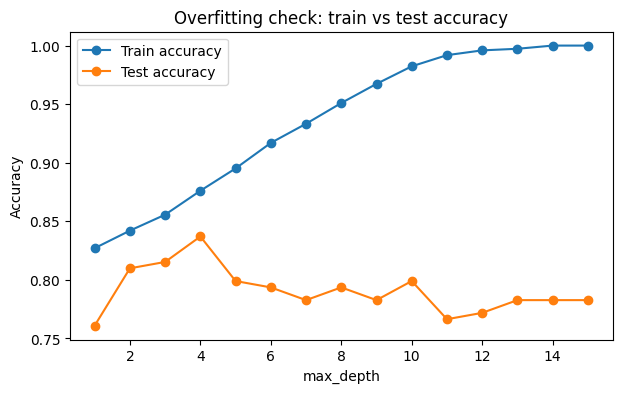


=== PRUNED TREE (max_depth=3) ===
Confusion matrix:
 [[275  53]
 [ 53 353]]
TN=275 FP=53 FN=53 TP=353
Train acc  : 0.8556
Test acc   : 0.8152
Precision  : 0.8542
Recall     : 0.8039
F1-score   : 0.8283

               precision    recall  f1-score   support

  No disease       0.77      0.83      0.80        82
     Disease       0.85      0.80      0.83       102

    accuracy                           0.82       184
   macro avg       0.81      0.82      0.81       184
weighted avg       0.82      0.82      0.82       184



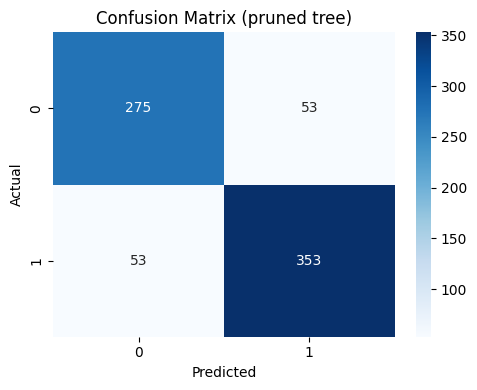

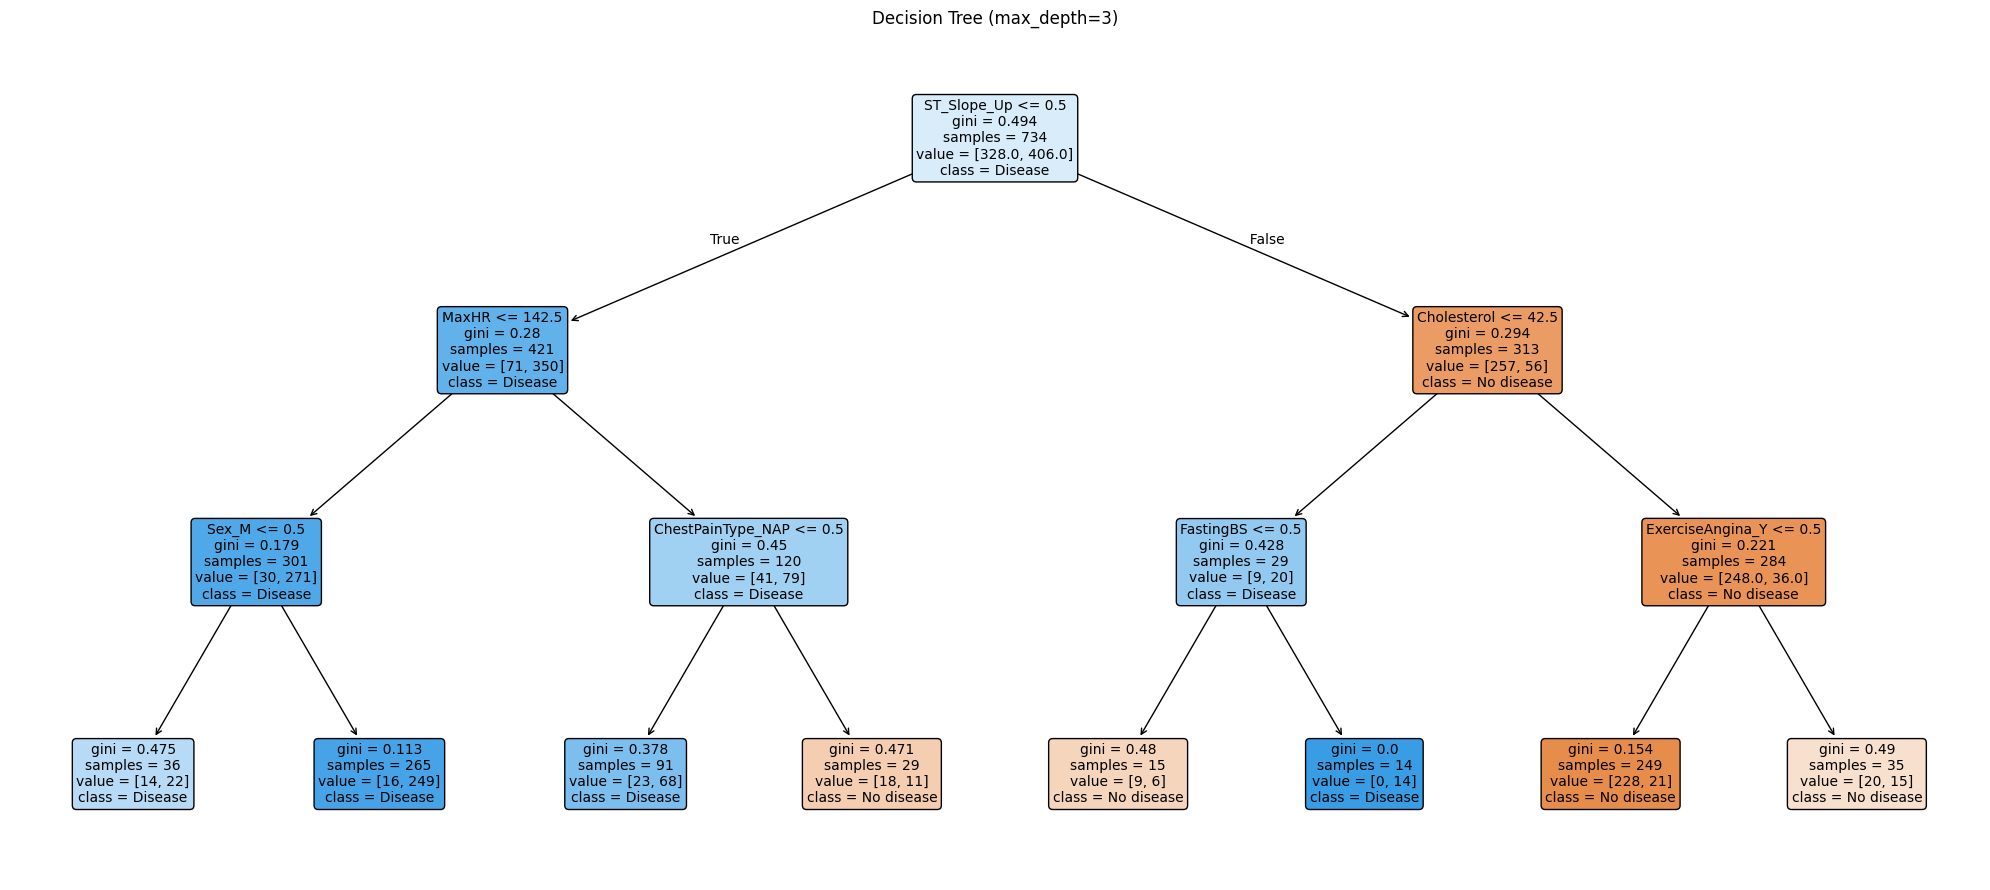


Tree as text rules:

|--- ST_Slope_Up <= 0.50
|   |--- MaxHR <= 142.50
|   |   |--- Sex_M <= 0.50
|   |   |   |--- class: 1
|   |   |--- Sex_M >  0.50
|   |   |   |--- class: 1
|   |--- MaxHR >  142.50
|   |   |--- ChestPainType_NAP <= 0.50
|   |   |   |--- class: 1
|   |   |--- ChestPainType_NAP >  0.50
|   |   |   |--- class: 0
|--- ST_Slope_Up >  0.50
|   |--- Cholesterol <= 42.50
|   |   |--- FastingBS <= 0.50
|   |   |   |--- class: 0
|   |   |--- FastingBS >  0.50
|   |   |   |--- class: 1
|   |--- Cholesterol >  42.50
|   |   |--- ExerciseAngina_Y <= 0.50
|   |   |   |--- class: 0
|   |   |--- ExerciseAngina_Y >  0.50
|   |   |   |--- class: 0


Featured importances:
 ST_Slope_Up          0.746126
Cholesterol          0.081400
MaxHR                0.049056
ExerciseAngina_Y     0.035502
Sex_M                0.033395
ChestPainType_NAP    0.029068
FastingBS            0.025452
dtype: float64


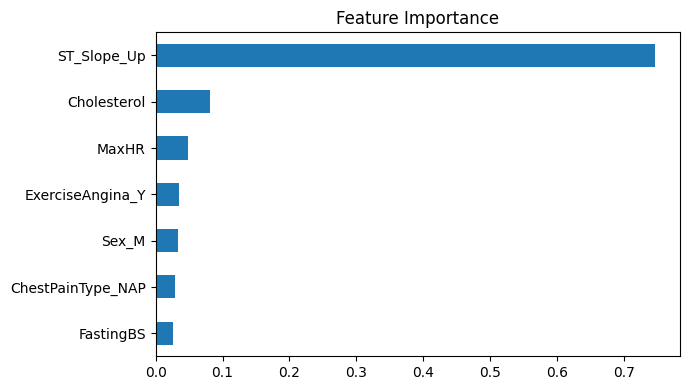

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text

from sklearn.metrics import (
    confusion_matrix, classification_report, accuracy_score,
    precision_score, recall_score, f1_score
)

# Load the dataset directly from Colab's workspace
df = pd.read_csv("heart.csv")
print(df.shape)
print(df.head())
print(df.info())
print("\nMissing values:", df.isnull().sum().sum())
print("\nClass balance (1 = heart disease):\n", df["HeartDisease"].value_counts())

# One-hot encode categorical features
cat_columns = ["Sex", "ChestPainType", "RestingECG", "ExerciseAngina", "ST_Slope"]
df = pd.get_dummies(df, drop_first=True, dtype=int)
X = df.drop(columns="HeartDisease")
y = df["HeartDisease"]

# Split into training and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Build an unrestricted tree
full_tree = DecisionTreeClassifier(random_state=42)
full_tree.fit(X_train, y_train)

print("\n=== UNRESTRICTED TREE ===")
print("Depth       :", full_tree.get_depth())
print("Leaves      :", full_tree.get_n_leaves())
print("Train acc   :", round(full_tree.score(X_train, y_train), 3))
print("Test acc    :", round(full_tree.score(X_test, y_test), 3))

# Check overfitting for different depths
depths = range(1, 16)
train_acc, test_acc = [], []
for d in depths:
    t = DecisionTreeClassifier(max_depth=d, random_state=42)
    t.fit(X_train, y_train)
    train_acc.append(t.score(X_train, y_train))
    test_acc.append(t.score(X_test, y_test))

plt.figure(figsize=(7, 4))
plt.plot(depths, train_acc, marker="o", label="Train accuracy")
plt.plot(depths, test_acc, marker="o", label="Test accuracy")
plt.xlabel("max_depth")
plt.ylabel("Accuracy")
plt.title("Overfitting check: train vs test accuracy")
plt.legend()
plt.savefig("depth_vs_accuracy.png")
plt.show()

tree = DecisionTreeClassifier(
    criterion="gini",
    max_depth=3,
    min_samples_leaf=10,
    min_samples_split=20,
    random_state=42
)
tree.fit(X_train, y_train)

y_train_pred = tree.predict(X_train)
cm = confusion_matrix(y_train, y_train_pred)
tn, fp, fn, tp = cm.ravel()
print("\n=== PRUNED TREE (max_depth=3) ===")
print("Confusion matrix:\n", cm)
print(f"TN={tn} FP={fp} FN={fn} TP={tp}")

# Predict and evaluate on test set
y_pred = tree.predict(X_test)
print("Train acc  :", round(tree.score(X_train, y_train), 4))
print("Test acc   :", round(accuracy_score(y_test, y_pred), 4))
print("Precision  :", round(precision_score(y_test, y_pred), 4))
print("Recall     :", round(recall_score(y_test, y_pred), 4))
print("F1-score   :", round(f1_score(y_test, y_pred), 4))

print("\n", classification_report(
    y_test,
    y_pred,
    target_names=["No disease", "Disease"]
))

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix (pruned tree)")
plt.tight_layout()
plt.savefig("confusion_matrix.png")
plt.show()


plt.figure(figsize=(20, 9))
plot_tree(
    tree,
    feature_names=X_train.columns,
    class_names=["No disease", "Disease"],
    filled=True,
    rounded=True,
    fontsize=10
)
plt.title("Decision Tree (max_depth=3)")
plt.tight_layout()
plt.savefig("decision_tree.png", dpi=150)
plt.show()
print("\nTree as text rules:\n")
print(export_text(tree, feature_names=list(X.columns)))


imp = pd.Series(tree.feature_importances_, index=X_train.columns)
imp.sort_values(ascending=False, inplace=True)
print("\nFeatured importances:\n", imp[imp > 0])
plt.figure(figsize=(7, 4))
imp[imp >0].sort_values().plot(kind="barh")
plt.title("Feature Importance")
plt.tight_layout()
plt.savefig("feature_importance.png")
plt.show()